# GRU and Transformer: computation versus measured evidence

This notebook separates synthetic, untrained forward passes from the committed historical benchmark aggregates. It does not train a model or download recordings or weights.

In [1]:
from pathlib import Path
import json
import numpy as np
import torch
from IPython.display import SVG, display
from ai_research_work.har import SensorCNN, HOFGRU, HOFTransformer, fuse_probabilities
torch.set_num_threads(1)
_ = torch.manual_seed(17)

## Same sensor branch, two video encoders

A six-channel [batch,128,6] sensor tensor goes to the CNN. RGB becomes Farneback flow then [batch,16,128] HOF. Both video encoders consume that same HOF representation. The Transformer is small and temporal; it does not operate directly on raw RGB pixels.

In [2]:
sensor = SensorCNN(27).eval()
video_models = {'hof_gru':HOFGRU(27).eval(), 'hof_transformer':HOFTransformer(27).eval()}
xs = torch.zeros(2,128,6); xv = torch.zeros(2,16,128)
ids = list(range(1,28)); labels = [f'demo class {i}' for i in ids]
def branch(p):
    return {'action_ids':ids,'labels':labels,'probabilities':p}
with torch.inference_mode():
    ps = torch.softmax(sensor(xs),dim=1).numpy()
    for name, model in video_models.items():
        pv = torch.softmax(model(xv),dim=1).numpy()
        print(name, 'logits shape:', tuple(model(xv).shape), 'fused classifier parameters:', sum(p.numel() for p in sensor.parameters())+sum(p.numel() for p in model.parameters()))
        for rule in ['arithmetic','product']:
            result = fuse_probabilities(branch(ps),branch(pv),fusion=rule)
            print(' ', rule, 'output:', result['probabilities'].shape, 'row sums:', result['probabilities'].sum(1).round(6).tolist(), 'acceptance:',result['acceptance'])
            assert np.array_equal(fuse_probabilities(branch(ps),None,fusion=rule)['probabilities'],ps)
            assert np.array_equal(fuse_probabilities(None,branch(pv),fusion=rule)['probabilities'],pv)
assert fuse_probabilities()['status']=='insufficient_input'

hof_gru logits shape: (2, 27) fused classifier parameters: 69142
  arithmetic output: (2, 27) row sums: [1.0, 1.0] acceptance: not_evaluated
  product output: (2, 27) row sums: [1.0, 1.0] acceptance: not_evaluated
hof_transformer logits shape: (2, 27) fused classifier parameters: 70646
  arithmetic output: (2, 27) row sums: [1.0, 1.0] acceptance: not_evaluated
  product output: (2, 27) row sums: [1.0, 1.0] acceptance: not_evaluated


## Historical 27-action benchmark (not synthetic outputs)

861 usable paired clips, eight people, eight seven-train/one-test LOSO folds, seeds 17/29/43. Average seeds within person, then people equally. Full-dataset coverage is not training/test reuse or one distributed all-subject checkpoint. Accuracy and macro-F1 below are percentages; NLL and Brier retain native units.

In [3]:
root = Path.cwd()
if not (root/'results/full_dataset_results.json').exists():
    root = root.parent
benchmark = json.loads((root/'results/full_dataset_results.json').read_text(encoding='utf-8'))
for row in benchmark['systems']:
    print(f"{row['model']:15} {row['fusion']:10} accuracy={100*row['accuracy']:.2f}% macro-F1={100*row['macro_f1']:.2f}% NLL={row['nll']:.6f} Brier={row['brier']:.6f}")

hof_gru         arithmetic accuracy=85.92% macro-F1=83.75% NLL=0.541258 Brier=0.239410
hof_gru         product    accuracy=89.17% macro-F1=87.52% NLL=0.694219 Brier=0.180640
hof_transformer arithmetic accuracy=87.85% macro-F1=86.19% NLL=0.488315 Brier=0.212298
hof_transformer product    accuracy=91.68% macro-F1=90.64% NLL=0.597152 Brier=0.148871


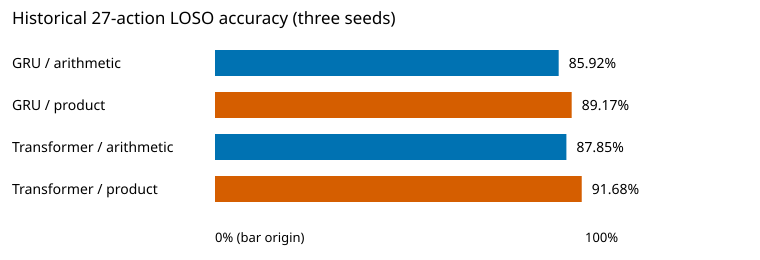

In [4]:
# A compact plot made only from committed aggregate values.
parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="760" height="260" viewBox="0 0 760 260">', '<rect width="760" height="260" fill="white"/>', '<text x="12" y="24" font-family="sans-serif" font-size="17">Historical 27-action LOSO accuracy (three seeds)</text>']
for i,row in enumerate(benchmark['systems']):
    y = 50 + i*42
    label = ('GRU' if row['model']=='hof_gru' else 'Transformer') + ' / ' + row['fusion']
    width = 400*row['accuracy']
    color = '#0072B2' if row['fusion']=='arithmetic' else '#D55E00'
    parts += [f'<text x="12" y="{y+18}" font-family="sans-serif" font-size="14">{label}</text>', f'<rect x="215" y="{y}" width="{width:.3f}" height="26" fill="{color}"/>', f'<text x="{225+width:.3f}" y="{y+18}" font-family="sans-serif" font-size="14">{100*row["accuracy"]:.2f}%</text>']
parts += ['<text x="215" y="242" font-family="sans-serif" font-size="13">0% (bar origin)</text>', '<text x="585" y="242" font-family="sans-serif" font-size="13">100%</text>', '</svg>']
display(SVG(''.join(parts)))

## Interpretation

Product has higher recorded accuracy and lower Brier, but worse NLL than arithmetic for each encoder. These metrics answer different questions. Both systems share their sensor branch. The historical CUDA LOSO comparison and CPU open-set study are different protocols and are not claimed bitwise identical. No synthetic accuracy is reported.

The separate seed-17 20-known/seven-unknown reliability study does not establish acceptance performance for the 91.68% benchmark classifier. Its recalibrated-rule results depend on operating point and include deployment-level losses of correct-known utility. Full-class inference therefore exposes scores without labelling them safe or accepted. No state-of-the-art, external-validation, streaming or product-latency claim is implied.